# Phase 3A Step 5 — Exploratory Data Analysis

## Customer Retention Intelligence System

This notebook performs **univariate descriptive analysis only** on the stratified
development split of the IBM Telco Customer Churn data. Its objectives are to:

1. verify the analytical environment and the development dataset;
2. understand structure, data types, completeness, uniqueness, and cardinality;
3. classify variables according to their statistical measurement role;
4. quantify and visualize the distributions of `tenure`, `MonthlyCharges`, and
   `TotalCharges`;
5. summarize categorical variables without analysing their relationship to the target.

### Scope and leakage guardrail

Only the configured **development split** is loaded. The held-out test split and the
full validated dataset are not read. This notebook does not alter data, engineer
features, impute, scale, encode, rebalance, train models, test hypotheses, or claim
causality. The target is identified and its cardinality is checked, but detailed target,
bivariate, and multivariate analysis is deliberately deferred.

## 1. Environment, project root, and configuration

Reproducibility begins by checking the interpreter and dependency versions. The project
root is discovered by walking upward until both `pyproject.toml` and `params.yaml` are
found. We then import and reuse `retention.utils.config.load_config` rather than parsing
project settings independently.

The development path is obtained from configuration. A strict assertion requires its
resolved filename to be `data/processed/development.parquet`; this is a defensive
data-leakage check, not a hard-coded loading shortcut.

In [1]:
# ruff: noqa: E501
import importlib.metadata as metadata
import sys
from pathlib import Path


def find_project_root(start: Path) -> Path:
    # Return the nearest parent containing the project's marker files.
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (
            candidate / "params.yaml"
        ).is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root from the current directory.")


PROJECT_ROOT = find_project_root(Path.cwd())
SRC_PATH = PROJECT_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from retention.utils.config import load_config  # noqa: E402

config = load_config(PROJECT_ROOT / "params.yaml")
configured_development_path = Path(config["data"]["development_path"])
development_path = (PROJECT_ROOT / configured_development_path).resolve()
expected_relative_path = Path("data/processed/development.parquet")

assert configured_development_path == expected_relative_path, (
    "Leakage guard failed: configured development path is unexpected."
)
assert development_path.is_file(), f"Development data not found: {development_path}"

required_packages = ["pandas", "numpy", "matplotlib", "seaborn", "scipy", "pyarrow"]
environment = {
    "Python": sys.version.split()[0],
    "Executable": sys.executable,
    **{package: metadata.version(package) for package in required_packages},
}

print(f"Project root: {PROJECT_ROOT}")
print(f"Configured input: {configured_development_path}")
print(f"Python 3.11 kernel: {sys.version_info[:2] == (3, 11)}")
for name, value in environment.items():
    print(f"{name}: {value}")

Project root: /Users/harshagarwal/Projects/ChurnRatePredictor
Configured input: data/processed/development.parquet
Python 3.11 kernel: True
Python: 3.11.14
Executable: /Users/harshagarwal/Projects/ChurnRatePredictor/.venv/bin/python
pandas: 2.3.3
numpy: 2.4.6
matplotlib: 3.11.2
seaborn: 0.13.2
scipy: 1.17.1
pyarrow: 26.0.1


## 2. Load the development dataset

Parquet preserves validated column types better than CSV and avoids repeating ingestion
logic. The load is intentionally read-only: subsequent analysis creates summaries and
figures but never writes back to the source data.

In [2]:
# ruff: noqa: E501
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update(
    {
        "figure.figsize": (10, 5.5),
        "axes.titleweight": "bold",
        "axes.labelsize": 11,
        "figure.dpi": 110,
    }
)

df = pd.read_parquet(development_path)
print(f"Loaded development data: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Loaded development data: 5,634 rows × 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,5334-JLAXU,Female,0,Yes,No,60,Yes,Yes,Fiber optic,Yes,Yes,No,No,No,Yes,Month-to-month,Yes,Credit card (automatic),94.100,"5,475.900",No
1,4573-JKNAE,Male,0,No,Yes,12,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),19.350,212.300,No
2,6923-JHPMP,Female,0,No,No,2,Yes,No,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,Yes,Electronic check,80.450,137.100,No
3,5524-KHNJP,Male,0,Yes,Yes,33,Yes,No,DSL,Yes,No,Yes,No,Yes,Yes,One year,No,Credit card (automatic),74.750,"2,453.300",No
4,5433-KYGHE,Female,0,No,Yes,14,Yes,Yes,Fiber optic,Yes,No,No,Yes,No,No,Month-to-month,Yes,Mailed check,86.000,"1,164.050",No


## 3. Dimensions, structure, data types, and memory

- A **row** represents one customer and a **column** represents an observed attribute.
- Data types determine valid operations: strings represent labels; integers may be
  counts or category codes; floating-point columns represent measured amounts.
- Memory is reported with `deep=True`, which includes referenced string data and is more
  realistic than the shallow object-container size.

An important limitation is that a storage type is not the same as a statistical type.
For example, `SeniorCitizen` is stored as an integer but is a binary category, so treating
its mean as a continuous measurement would be misleading.

In [3]:
# ruff: noqa: E501
dimension_summary = pd.DataFrame(
    {
        "metric": ["Rows", "Columns", "Cells", "Deep memory (MiB)"],
        "value": [
            df.shape[0],
            df.shape[1],
            df.size,
            df.memory_usage(deep=True).sum() / 1024**2,
        ],
    }
)
dtype_summary = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "memory_KiB": df.memory_usage(deep=True, index=False) / 1024,
    }
)
display(dimension_summary)
display(dtype_summary)

,metric,value
0,Rows,"5,634.000"
1,Columns,21.000
2,Cells,"118,314.000"
3,Deep memory (MiB),5.934


,dtype,non_null,memory_KiB
customerID,string,5634,368.631
gender,string,5634,341.033
SeniorCitizen,int64,5634,44.016
Partner,string,5634,327.250
Dependents,string,5634,326.285
tenure,int64,5634,44.016
PhoneService,string,5634,329.601
MultipleLines,string,5634,334.167
InternetService,string,5634,348.415
OnlineSecurity,string,5634,346.227


## 4. Missing values, duplicates, and identifier integrity

For feature $j$, the missing percentage is

$$\text{Missing\%}_j = \frac{\text{number of missing values in }j}{n}\times 100.$$

Missingness matters because many statistical and machine-learning methods either reject
missing values or silently analyse a smaller, potentially biased subset. A zero count
means no encoded nulls are present; it does **not** prove that every recorded value is
semantically correct. Placeholder strings or validation-time substitutions can still
exist.

Duplicate rows can over-weight customers. The business key `customerID` should be
complete and unique so that one customer does not appear multiple times in this snapshot.

In [4]:
# ruff: noqa: E501
missing_summary = pd.DataFrame(
    {
        "missing_count": df.isna().sum(),
        "missing_percent": df.isna().mean().mul(100),
    }
).sort_values(["missing_count", "missing_percent"], ascending=False)

id_column = config["data"]["id_column"]
integrity_summary = pd.Series(
    {
        "duplicate_rows": int(df.duplicated().sum()),
        "missing_customer_ids": int(df[id_column].isna().sum()),
        "duplicate_customer_ids": int(df[id_column].duplicated().sum()),
        "unique_customer_ids": int(df[id_column].nunique(dropna=True)),
        "rows": len(df),
    },
    name="value",
).to_frame()

display(missing_summary)
display(integrity_summary)
display(
    Markdown(
        f"**Observed result:** all {df.shape[1]} columns contain "
        f"{int(df.isna().sum().sum())} encoded missing values in total. There are "
        f"{int(df.duplicated().sum())} duplicate rows and "
        f"{int(df[id_column].duplicated().sum())} duplicate customer IDs among "
        f"{len(df):,} records."
    )
)

,missing_count,missing_percent
customerID,0,0.000
gender,0,0.000
SeniorCitizen,0,0.000
Partner,0,0.000
Dependents,0,0.000
tenure,0,0.000
PhoneService,0,0.000
MultipleLines,0,0.000
InternetService,0,0.000
OnlineSecurity,0,0.000


,value
duplicate_rows,0
missing_customer_ids,0
duplicate_customer_ids,0
unique_customer_ids,5634
rows,5634


**Observed result:** all 21 columns contain 0 encoded missing values in total. There are 0 duplicate rows and 0 duplicate customer IDs among 5,634 records.

## 5. Cardinality and statistical variable roles

**Cardinality** is the number of distinct observed values:

$$K_j = \left|\{x_{1j},x_{2j},\ldots,x_{nj}\}\right|.$$

It helps distinguish identifiers, categories, discrete measurements, and near-continuous
measurements. High cardinality is not inherently bad: it is expected for a customer ID
and for monetary totals. Cardinality depends on sample size and precision, so it should
be interpreted together with domain meaning.

Variable roles used here:

- **Identifier:** label for a record, excluded from statistical features.
- **Target:** prediction outcome, separated to prevent accidental leakage.
- **Binary categorical:** exactly two conceptual states; `SeniorCitizen` belongs here
  despite its integer storage.
- **Nominal:** unordered labels.
- **Ordinal:** ordered labels; `Contract` has an increasing commitment duration.
- **Discrete numerical:** count-like values; `tenure` is completed months from 0 to 72.
- **Continuous numerical:** measured monetary values, represented with decimals.

In [5]:
# ruff: noqa: E501
target_column = config["data"]["target_column"]
identifier = [id_column]
target = [target_column]
binary_categorical = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "PaperlessBilling",
]
ordinal_categorical = ["Contract"]
nominal_categorical = [
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "PaymentMethod",
]
discrete_numerical = ["tenure"]
continuous_numerical = ["MonthlyCharges", "TotalCharges"]
numerical_features = discrete_numerical + continuous_numerical
categorical_features = binary_categorical + ordinal_categorical + nominal_categorical

assigned_columns = set(identifier + target + categorical_features + numerical_features)
assert assigned_columns == set(df.columns), (
    f"Unclassified={set(df.columns) - assigned_columns}; "
    f"unknown={assigned_columns - set(df.columns)}"
)
assert (
    "SeniorCitizen" in binary_categorical and "SeniorCitizen" not in numerical_features
)

role_rows = []
for role, columns in {
    "Identifier": identifier,
    "Target": target,
    "Binary categorical": binary_categorical,
    "Ordinal categorical": ordinal_categorical,
    "Nominal categorical": nominal_categorical,
    "Discrete numerical": discrete_numerical,
    "Continuous numerical": continuous_numerical,
}.items():
    role_rows.extend(
        {"feature": column, "role": role, "storage_dtype": str(df[column].dtype)}
        for column in columns
    )

cardinality = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "unique_count": df.nunique(dropna=False),
        "unique_percent": df.nunique(dropna=False).div(len(df)).mul(100),
    }
).sort_values("unique_count")

display(cardinality)
display(pd.DataFrame(role_rows).sort_values(["role", "feature"]))

,dtype,unique_count,unique_percent
Churn,string,2,0.035
gender,string,2,0.035
SeniorCitizen,int64,2,0.035
Partner,string,2,0.035
Dependents,string,2,0.035
PaperlessBilling,string,2,0.035
PhoneService,string,2,0.035
Contract,string,3,0.053
StreamingMovies,string,3,0.053
StreamingTV,string,3,0.053


,feature,role,storage_dtype
5,Dependents,Binary categorical,string
7,PaperlessBilling,Binary categorical,string
4,Partner,Binary categorical,string
6,PhoneService,Binary categorical,string
3,SeniorCitizen,Binary categorical,int64
2,gender,Binary categorical,string
19,MonthlyCharges,Continuous numerical,float64
20,TotalCharges,Continuous numerical,float64
18,tenure,Discrete numerical,int64
0,customerID,Identifier,string


# 6. Numerical descriptive statistics

## 6.1 Central tendency

For observations $x_1,\ldots,x_n$:

$$\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i,$$

the **median** is the 50th percentile, and the **mode** is the most frequent value.
The mean uses every value but is sensitive to extremes; the median is resistant to
extreme values; the mode is particularly meaningful for discrete tenure but may be
unstable for finely measured amounts. Multiple modes are possible.

The signed difference $\bar{x}-\tilde{x}$ is a simple distribution clue, not a complete
skewness measure: positive values often accompany a longer right tail, while negative
values often accompany a longer left tail. Telecom use: these summaries describe a
typical customer's relationship length and billing level, informing segmentation and
capacity/revenue planning without implying why customers behave as they do.

In [6]:
# ruff: noqa: E501
central_rows = []
for column in numerical_features:
    series = df[column]
    modes = series.mode().tolist()
    central_rows.append(
        {
            "feature": column,
            "mean": series.mean(),
            "median": series.median(),
            "mode": ", ".join(f"{value:g}" for value in modes),
            "number_of_modes": len(modes),
            "mean_minus_median": series.mean() - series.median(),
        }
    )
central_tendency = pd.DataFrame(central_rows).set_index("feature")
display(central_tendency)

direction = {}
for column in numerical_features:
    difference = central_tendency.loc[column, "mean_minus_median"]
    direction[column] = (
        "mean above median"
        if difference > 0
        else "mean below median"
        if difference < 0
        else "mean equal to median"
    )
display(
    Markdown(
        "**Development-data interpretation.** "
        f"Tenure averages {df['tenure'].mean():.2f} months versus a median of "
        f"{df['tenure'].median():.0f} ({direction['tenure']}); the modal tenure is "
        f"{df['tenure'].mode().iloc[0]:.0f} month, indicating a concentration of newly "
        f"acquired customers. Monthly charges average {df['MonthlyCharges'].mean():,.2f} "
        f"dataset currency units versus a {df['MonthlyCharges'].median():,.2f} median "
        f"({direction['MonthlyCharges']}). Total charges average "
        f"{df['TotalCharges'].mean():,.2f}, far above the {df['TotalCharges'].median():,.2f} "
        "median, consistent with a substantial upper tail of long-tenured/high-spend "
        "customers. The source dataset does not document a currency."
    )
)

,mean,median,mode,number_of_modes,mean_minus_median
feature,,,,,
tenure,32.350,29.000,1,1,3.350
MonthlyCharges,65.033,70.525,20.05,1,-5.492
TotalCharges,"2,291.430","1,395.525",0,1,895.905


**Development-data interpretation.** Tenure averages 32.35 months versus a median of 29 (mean above median); the modal tenure is 1 month, indicating a concentration of newly acquired customers. Monthly charges average 65.03 dataset currency units versus a 70.53 median (mean below median). Total charges average 2,291.43, far above the 1,395.53 median, consistent with a substantial upper tail of long-tenured/high-spend customers. The source dataset does not document a currency.

## 6.2 Dispersion

The sample variance and standard deviation are

$$s^2=\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})^2,\qquad s=\sqrt{s^2}.$$

The range is $\max(x)-\min(x)$. The coefficient of variation (CV) is

$$CV=\frac{s}{\bar{x}}\times100\%.$$

We use $n-1$ (`ddof=1`) to estimate population variability from a sample. Standard
deviation stays in the original unit; variance is in squared units; the CV enables
relative comparison across positive ratio-scale variables. The CV is unstable when the
mean is zero or close to zero and is not suitable for arbitrary-origin scales. Range is
very sensitive to extremes. In telecom, high charge variability may represent diverse
plans, service bundles, and customer lifetimes; it does not establish their causes.

In [7]:
# ruff: noqa: E501
dispersion_rows = []
for column in numerical_features:
    series = df[column]
    dispersion_rows.append(
        {
            "feature": column,
            "minimum": series.min(),
            "maximum": series.max(),
            "range": series.max() - series.min(),
            "sample_variance": series.var(ddof=1),
            "standard_deviation": series.std(ddof=1),
            "coefficient_of_variation_percent": series.std(ddof=1)
            / series.mean()
            * 100,
        }
    )
dispersion = pd.DataFrame(dispersion_rows).set_index("feature")
display(dispersion)
display(
    Markdown(
        "**Development-data interpretation.** Relative dispersion is highest for "
        f"`TotalCharges` (CV {dispersion.loc['TotalCharges', 'coefficient_of_variation_percent']:.1f}%), "
        f"followed by `tenure` ({dispersion.loc['tenure', 'coefficient_of_variation_percent']:.1f}%) "
        f"and `MonthlyCharges` ({dispersion.loc['MonthlyCharges', 'coefficient_of_variation_percent']:.1f}%). "
        "Cumulative charges therefore vary almost as much as their mean, which is plausible "
        "because they combine duration and recurring price."
    )
)

,minimum,maximum,range,sample_variance,standard_deviation,coefficient_of_variation_percent
feature,,,,,,
tenure,0.000,72.000,72.000,604.306,24.583,75.990
MonthlyCharges,18.400,118.750,100.350,901.390,30.023,46.166
TotalCharges,0.000,"8,684.800","8,684.800","5,185,441.470","2,277.156",99.377


**Development-data interpretation.** Relative dispersion is highest for `TotalCharges` (CV 99.4%), followed by `tenure` (76.0%) and `MonthlyCharges` (46.2%). Cumulative charges therefore vary almost as much as their mean, which is plausible because they combine duration and recurring price.

## 6.3 Position: quartiles, percentiles, and IQR

The $p$th quantile $Q(p)$ is a value at or below which approximately proportion $p$ of
observations fall. Quartiles are $Q_1=Q(0.25)$, $Q_2=Q(0.50)$, and $Q_3=Q(0.75)$.

$$IQR=Q_3-Q_1.$$

Percentiles describe position without assuming a normal distribution, and the IQR
summarizes the middle 50% robustly. Quantile values depend slightly on interpolation
rules and can repeat for discrete or bounded variables—here tenure's upper percentiles
can coincide at the 72-month ceiling. Business use: percentiles support customer-tier
thresholds and contextualize an individual bill, but thresholds should not be adopted
as policy without later outcome and cost analysis.

In [8]:
# ruff: noqa: E501
probabilities = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
percentiles = df[numerical_features].quantile(probabilities).T
percentiles.columns = [f"p{int(p * 100):02d}" for p in probabilities]
percentiles["IQR"] = percentiles["p75"] - percentiles["p25"]
display(percentiles)
display(
    Markdown(
        "**Development-data interpretation.** The middle 50% spans "
        f"{percentiles.loc['tenure', 'p25']:.0f}–{percentiles.loc['tenure', 'p75']:.0f} months "
        f"(IQR {percentiles.loc['tenure', 'IQR']:.0f}), "
        f"{percentiles.loc['MonthlyCharges', 'p25']:.2f}–"
        f"{percentiles.loc['MonthlyCharges', 'p75']:.2f} monthly-charge units, and "
        f"{percentiles.loc['TotalCharges', 'p25']:.2f}–"
        f"{percentiles.loc['TotalCharges', 'p75']:.2f} total-charge units. The 95th and "
        f"99th tenure percentiles are both {percentiles.loc['tenure', 'p99']:.0f} months, "
        "showing the dataset's upper tenure boundary."
    )
)

,p05,p10,p25,p50,p75,p90,p95,p99,IQR
tenure,1.000,2.000,9.000,29.000,55.000,69.000,72.000,72.000,46.000
MonthlyCharges,19.650,20.050,38.312,70.525,89.900,102.585,107.567,114.984,51.588
TotalCharges,48.698,80.880,393.225,"1,395.525","3,832.900","6,000.025","6,975.775","8,064.280","3,439.675"


**Development-data interpretation.** The middle 50% spans 9–55 months (IQR 46), 38.31–89.90 monthly-charge units, and 393.22–3832.90 total-charge units. The 95th and 99th tenure percentiles are both 72 months, showing the dataset's upper tenure boundary.

## 6.4 Distribution shape: skewness and excess kurtosis

The adjusted sample skewness estimates standardized third-moment asymmetry:

$$g_1 \approx \frac{\mathbb{E}[(X-\mu)^3]}{\sigma^3}.$$

- $g_1\approx0$: approximately symmetric;
- $g_1>0$: positive/right skew (longer right tail);
- $g_1<0$: negative/left skew (longer left tail).

Excess kurtosis is standardized fourth-moment kurtosis minus 3:

$$\text{Excess kurtosis}=\frac{\mathbb{E}[(X-\mu)^4]}{\sigma^4}-3.$$

Positive excess kurtosis indicates heavier tails/more extreme observations than a normal
distribution; negative values indicate lighter tails/flatter shape. These moment
statistics are sensitive to extreme values, and near-zero values do not prove normality.
For bounded, discrete tenure, shape must be interpreted with its histogram and ECDF.
No formal normality or hypothesis test is performed here.

In [9]:
# ruff: noqa: E501
def skew_label(value: float) -> str:
    if value > 0.5:
        return "positively (right) skewed"
    if value < -0.5:
        return "negatively (left) skewed"
    return "approximately symmetric to mildly skewed"


def tail_label(value: float) -> str:
    if value > 0.5:
        return "heavier-tailed/more peaked than normal"
    if value < -0.5:
        return "lighter-tailed/flatter than normal"
    return "near normal kurtosis (tail shape still requires a plot)"


shape_rows = []
for column in numerical_features:
    skewness = stats.skew(df[column], bias=False)
    excess_kurtosis = stats.kurtosis(df[column], fisher=True, bias=False)
    shape_rows.append(
        {
            "feature": column,
            "skewness": skewness,
            "skew_interpretation": skew_label(skewness),
            "excess_kurtosis": excess_kurtosis,
            "tail_interpretation": tail_label(excess_kurtosis),
        }
    )
distribution_shape = pd.DataFrame(shape_rows).set_index("feature")
display(distribution_shape)
display(
    Markdown(
        "**Development-data interpretation.** `tenure` has mild positive skew "
        f"({distribution_shape.loc['tenure', 'skewness']:.3f}); `MonthlyCharges` has mild "
        f"negative skew ({distribution_shape.loc['MonthlyCharges', 'skewness']:.3f}); and "
        f"`TotalCharges` is clearly right-skewed ({distribution_shape.loc['TotalCharges', 'skewness']:.3f}). "
        "All three excess-kurtosis estimates are negative in this split, so their shapes are "
        "flatter/lighter-tailed than a normal reference by this moment measure. This does not "
        "mean high total charges are errors; they may be valid accumulated bills."
    )
)

,skewness,skew_interpretation,excess_kurtosis,tail_interpretation
feature,,,,
tenure,0.241,approximately symmetric to mildly skewed,-1.387,lighter-tailed/flatter than normal
MonthlyCharges,-0.235,approximately symmetric to mildly skewed,-1.240,lighter-tailed/flatter than normal
TotalCharges,0.962,positively (right) skewed,-0.227,near normal kurtosis (tail shape still require...


**Development-data interpretation.** `tenure` has mild positive skew (0.241); `MonthlyCharges` has mild negative skew (-0.235); and `TotalCharges` is clearly right-skewed (0.962). All three excess-kurtosis estimates are negative in this split, so their shapes are flatter/lighter-tailed than a normal reference by this moment measure. This does not mean high total charges are errors; they may be valid accumulated bills.

# 7. Numerical visualizations

## 7.1 Histograms, density, and reference lines

A histogram partitions values into bins and shows counts. Bin width affects apparent
shape, so it is not a unique representation. A kernel density estimate (KDE) is a
smoothed estimate

$$\hat f_h(x)=\frac{1}{nh}\sum_{i=1}^n K\left(\frac{x-x_i}{h}\right),$$

where bandwidth $h$ controls smoothing. KDE assumes an underlying continuous density and
can extend beyond real bounds. It is therefore shown only for monetary variables—not for
integer-valued `tenure`, where smoothing can imply impossible fractional months or values
outside 0–72. Dashed/dotted lines compare mean and median; separation visually suggests
asymmetry but does not diagnose its cause.

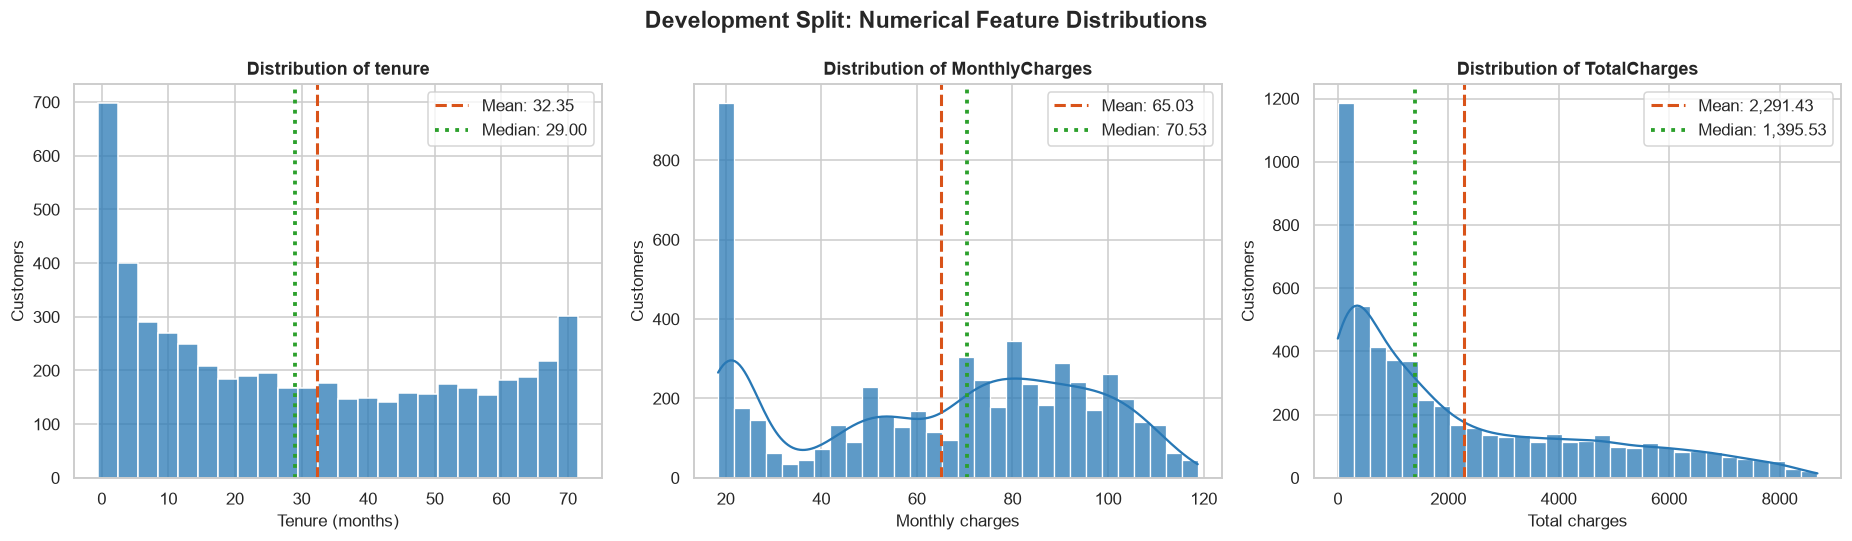

In [10]:
# ruff: noqa: E501
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
plot_settings = {
    "tenure": {
        "bins": np.arange(-0.5, 73.5, 3),
        "kde": False,
        "label": "Tenure (months)",
    },
    "MonthlyCharges": {"bins": 30, "kde": True, "label": "Monthly charges"},
    "TotalCharges": {"bins": 30, "kde": True, "label": "Total charges"},
}
for axis, (column, settings) in zip(axes, plot_settings.items(), strict=True):
    sns.histplot(
        data=df,
        x=column,
        bins=settings["bins"],
        kde=settings["kde"],
        color="#2878B5",
        edgecolor="white",
        alpha=0.75,
        ax=axis,
    )
    axis.axvline(
        df[column].mean(),
        color="#D95319",
        linestyle="--",
        linewidth=2,
        label=f"Mean: {df[column].mean():,.2f}",
    )
    axis.axvline(
        df[column].median(),
        color="#2CA02C",
        linestyle=":",
        linewidth=2.5,
        label=f"Median: {df[column].median():,.2f}",
    )
    axis.set(
        title=f"Distribution of {column}", xlabel=settings["label"], ylabel="Customers"
    )
    axis.legend()
fig.suptitle(
    "Development Split: Numerical Feature Distributions", fontsize=15, fontweight="bold"
)
fig.tight_layout()
plt.show()

**How to read the figure.** Bar height is the number of customers in a value interval;
the density curve summarizes shape but not customer counts. `tenure` shows concentrations
near the newest and longest-tenured customers. The monthly-charge histogram is broad and
not well represented by one normal bell curve, plausibly reflecting different service
packages. Total charges have a strong right tail because cumulative spend can grow with
both tenure and monthly price. These are descriptive patterns, not evidence of causal
relationships.

## 7.2 Box plots and violin plots

A box plot displays $Q_1$, median, $Q_3$, and whiskers commonly extending to the most
extreme observations within $1.5\times IQR$ of the quartiles. Points beyond whiskers are
**statistical outlier candidates**, not automatically errors. A violin plot mirrors a KDE
to show distribution density and embeds quartile information.

Because the three variables have different units and ranges, each uses a separate axis.
Violin smoothing is useful for the monetary variables but should be interpreted cautiously
for discrete tenure. Operationally, unusually high cumulative charges may identify
valuable long-standing accounts; deleting them mechanically would destroy valid business
information.

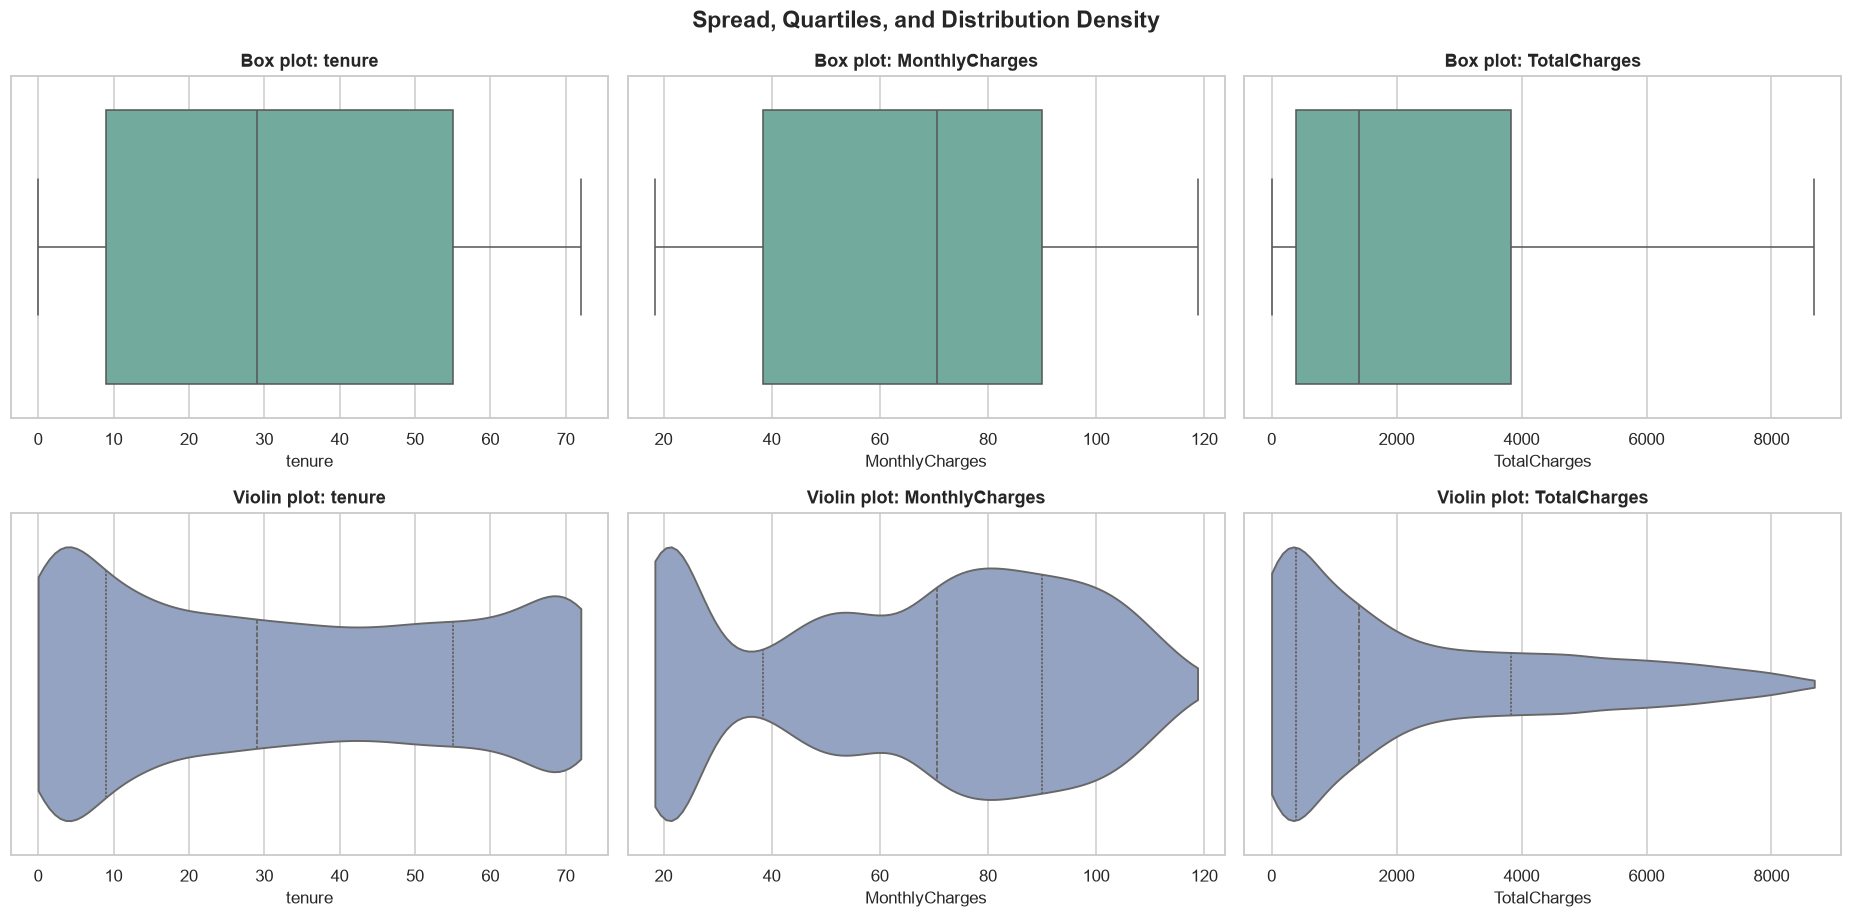

In [11]:
# ruff: noqa: E501
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
for column, top_axis, bottom_axis in zip(
    numerical_features, axes[0], axes[1], strict=True
):
    sns.boxplot(data=df, x=column, color="#69B3A2", ax=top_axis)
    top_axis.set(title=f"Box plot: {column}", xlabel=column)
    sns.violinplot(
        data=df, x=column, color="#8DA0CB", inner="quartile", cut=0, ax=bottom_axis
    )
    bottom_axis.set(title=f"Violin plot: {column}", xlabel=column)
fig.suptitle(
    "Spread, Quartiles, and Distribution Density", fontsize=15, fontweight="bold"
)
fig.tight_layout()
plt.show()

## 7.3 Empirical cumulative distribution function (ECDF)

The ECDF is

$$\widehat F_n(x)=\frac{1}{n}\sum_{i=1}^{n}\mathbf{1}(x_i\le x).$$

At any $x$, the vertical value is the observed proportion at or below $x$. It is
non-parametric, preserves all observations, and avoids histogram bins or KDE bandwidth.
Steps are expected for repeated/discrete values. It supports questions such as “what
fraction of customers have tenure no more than 12 months?” but does not explain why.

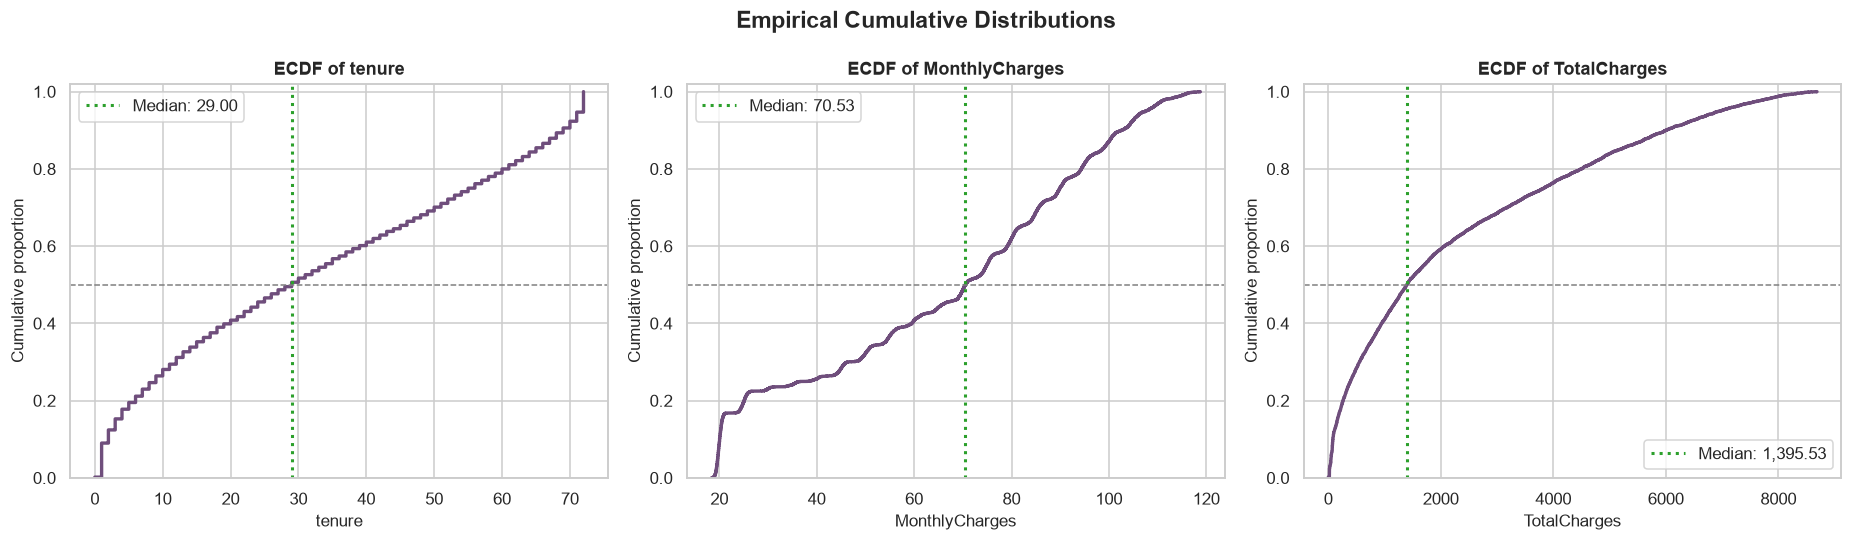

,observed_share
Tenure ≤ 12 months (%),31.168
Monthly charges ≤ median (%),50.000
"Total charges ≤ 1,000 (%)",41.072


In [12]:
# ruff: noqa: E501
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for axis, column in zip(axes, numerical_features, strict=True):
    sns.ecdfplot(data=df, x=column, color="#6F4E7C", linewidth=2.2, ax=axis)
    axis.axhline(0.5, color="grey", linestyle="--", linewidth=1)
    axis.axvline(
        df[column].median(),
        color="#2CA02C",
        linestyle=":",
        linewidth=2,
        label=f"Median: {df[column].median():,.2f}",
    )
    axis.set(
        title=f"ECDF of {column}",
        xlabel=column,
        ylabel="Cumulative proportion",
        ylim=(0, 1.02),
    )
    axis.legend()
fig.suptitle("Empirical Cumulative Distributions", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

ecdf_business = pd.Series(
    {
        "Tenure ≤ 12 months (%)": (df["tenure"] <= 12).mean() * 100,
        "Monthly charges ≤ median (%)": (
            df["MonthlyCharges"] <= df["MonthlyCharges"].median()
        ).mean()
        * 100,
        "Total charges ≤ 1,000 (%)": (df["TotalCharges"] <= 1000).mean() * 100,
    },
    name="observed_share",
)
display(ecdf_business.to_frame())

# 8. Categorical descriptive statistics

For category $c$, frequency is $n_c=\sum_i \mathbf{1}(x_i=c)$ and relative frequency is

$$p_c=\frac{n_c}{n},\qquad \text{percentage}_c=100p_c.$$

The mode is the category with the largest $n_c$; cardinality is the number of categories.
Counts communicate operational volume, while percentages make comparisons across samples
easier. Categories are labels, so means and standard deviations are inappropriate—even
for integer-coded `SeniorCitizen`. A dominant category can create imbalance, but no
balancing is performed here. Small groups require caution because percentages can look
important despite limited counts.

The target is kept separate from feature summaries. Its two-class cardinality is verified,
but detailed target distribution and relationships are intentionally outside this step.

In [13]:
# ruff: noqa: E501
categorical_summary_rows = []
frequency_tables = {}
for column in categorical_features:
    counts = df[column].value_counts(dropna=False)
    frequencies = pd.DataFrame(
        {
            "count": counts,
            "relative_frequency": counts / len(df),
            "percentage": counts / len(df) * 100,
        }
    )
    frequencies.index.name = column
    frequency_tables[column] = frequencies
    categorical_summary_rows.append(
        {
            "feature": column,
            "cardinality": df[column].nunique(dropna=False),
            "mode": df[column].mode(dropna=False).iloc[0],
            "mode_count": counts.iloc[0],
            "mode_percentage": counts.iloc[0] / len(df) * 100,
            "categories": " | ".join(map(str, counts.index.tolist())),
        }
    )

categorical_summary = pd.DataFrame(categorical_summary_rows).set_index("feature")
display(categorical_summary)

for column in categorical_features:
    display(Markdown(f"**{column}**"))
    display(frequency_tables[column])

target_cardinality_check = pd.Series(
    {
        "target_column": target_column,
        "cardinality": df[target_column].nunique(dropna=False),
        "missing": int(df[target_column].isna().sum()),
    },
    name="target_check",
)
display(target_cardinality_check.to_frame())

,cardinality,mode,mode_count,mode_percentage,categories
feature,,,,,
gender,2,Male,2862,50.799,Male | Female
SeniorCitizen,2,0,4726,83.884,0 | 1
Partner,2,No,2936,52.112,No | Yes
Dependents,2,No,3924,69.649,No | Yes
PhoneService,2,Yes,5105,90.611,Yes | No
PaperlessBilling,2,Yes,3365,59.727,Yes | No
Contract,3,Month-to-month,3095,54.934,Month-to-month | Two year | One year
MultipleLines,3,No,2730,48.456,No | Yes | No phone service
InternetService,3,Fiber optic,2493,44.249,Fiber optic | DSL | No


**gender**

,count,relative_frequency,percentage
gender,,,
Male,2862,0.508,50.799
Female,2772,0.492,49.201


**SeniorCitizen**

,count,relative_frequency,percentage
SeniorCitizen,,,
0,4726,0.839,83.884
1,908,0.161,16.116


**Partner**

... (24 outputs left out)

,count,relative_frequency,percentage
StreamingMovies,,,
No,2224,0.395,39.475
Yes,2203,0.391,39.102
No internet service,1207,0.214,21.424


**PaymentMethod**

,count,relative_frequency,percentage
PaymentMethod,,,
Electronic check,1877,0.333,33.316
Mailed check,1296,0.230,23.003
Bank transfer (automatic),1246,0.221,22.116
Credit card (automatic),1215,0.216,21.565


,target_check
target_column,Churn
cardinality,2
missing,0


## 8.1 Categorical frequency bar charts

Each bar is a customer count. Ordering bars by observed frequency makes dominant service
states easy to compare, while keeping every feature in its own panel prevents categories
with different meanings from being placed on a common numeric scale. Long labels are
wrapped/rotated for readability.

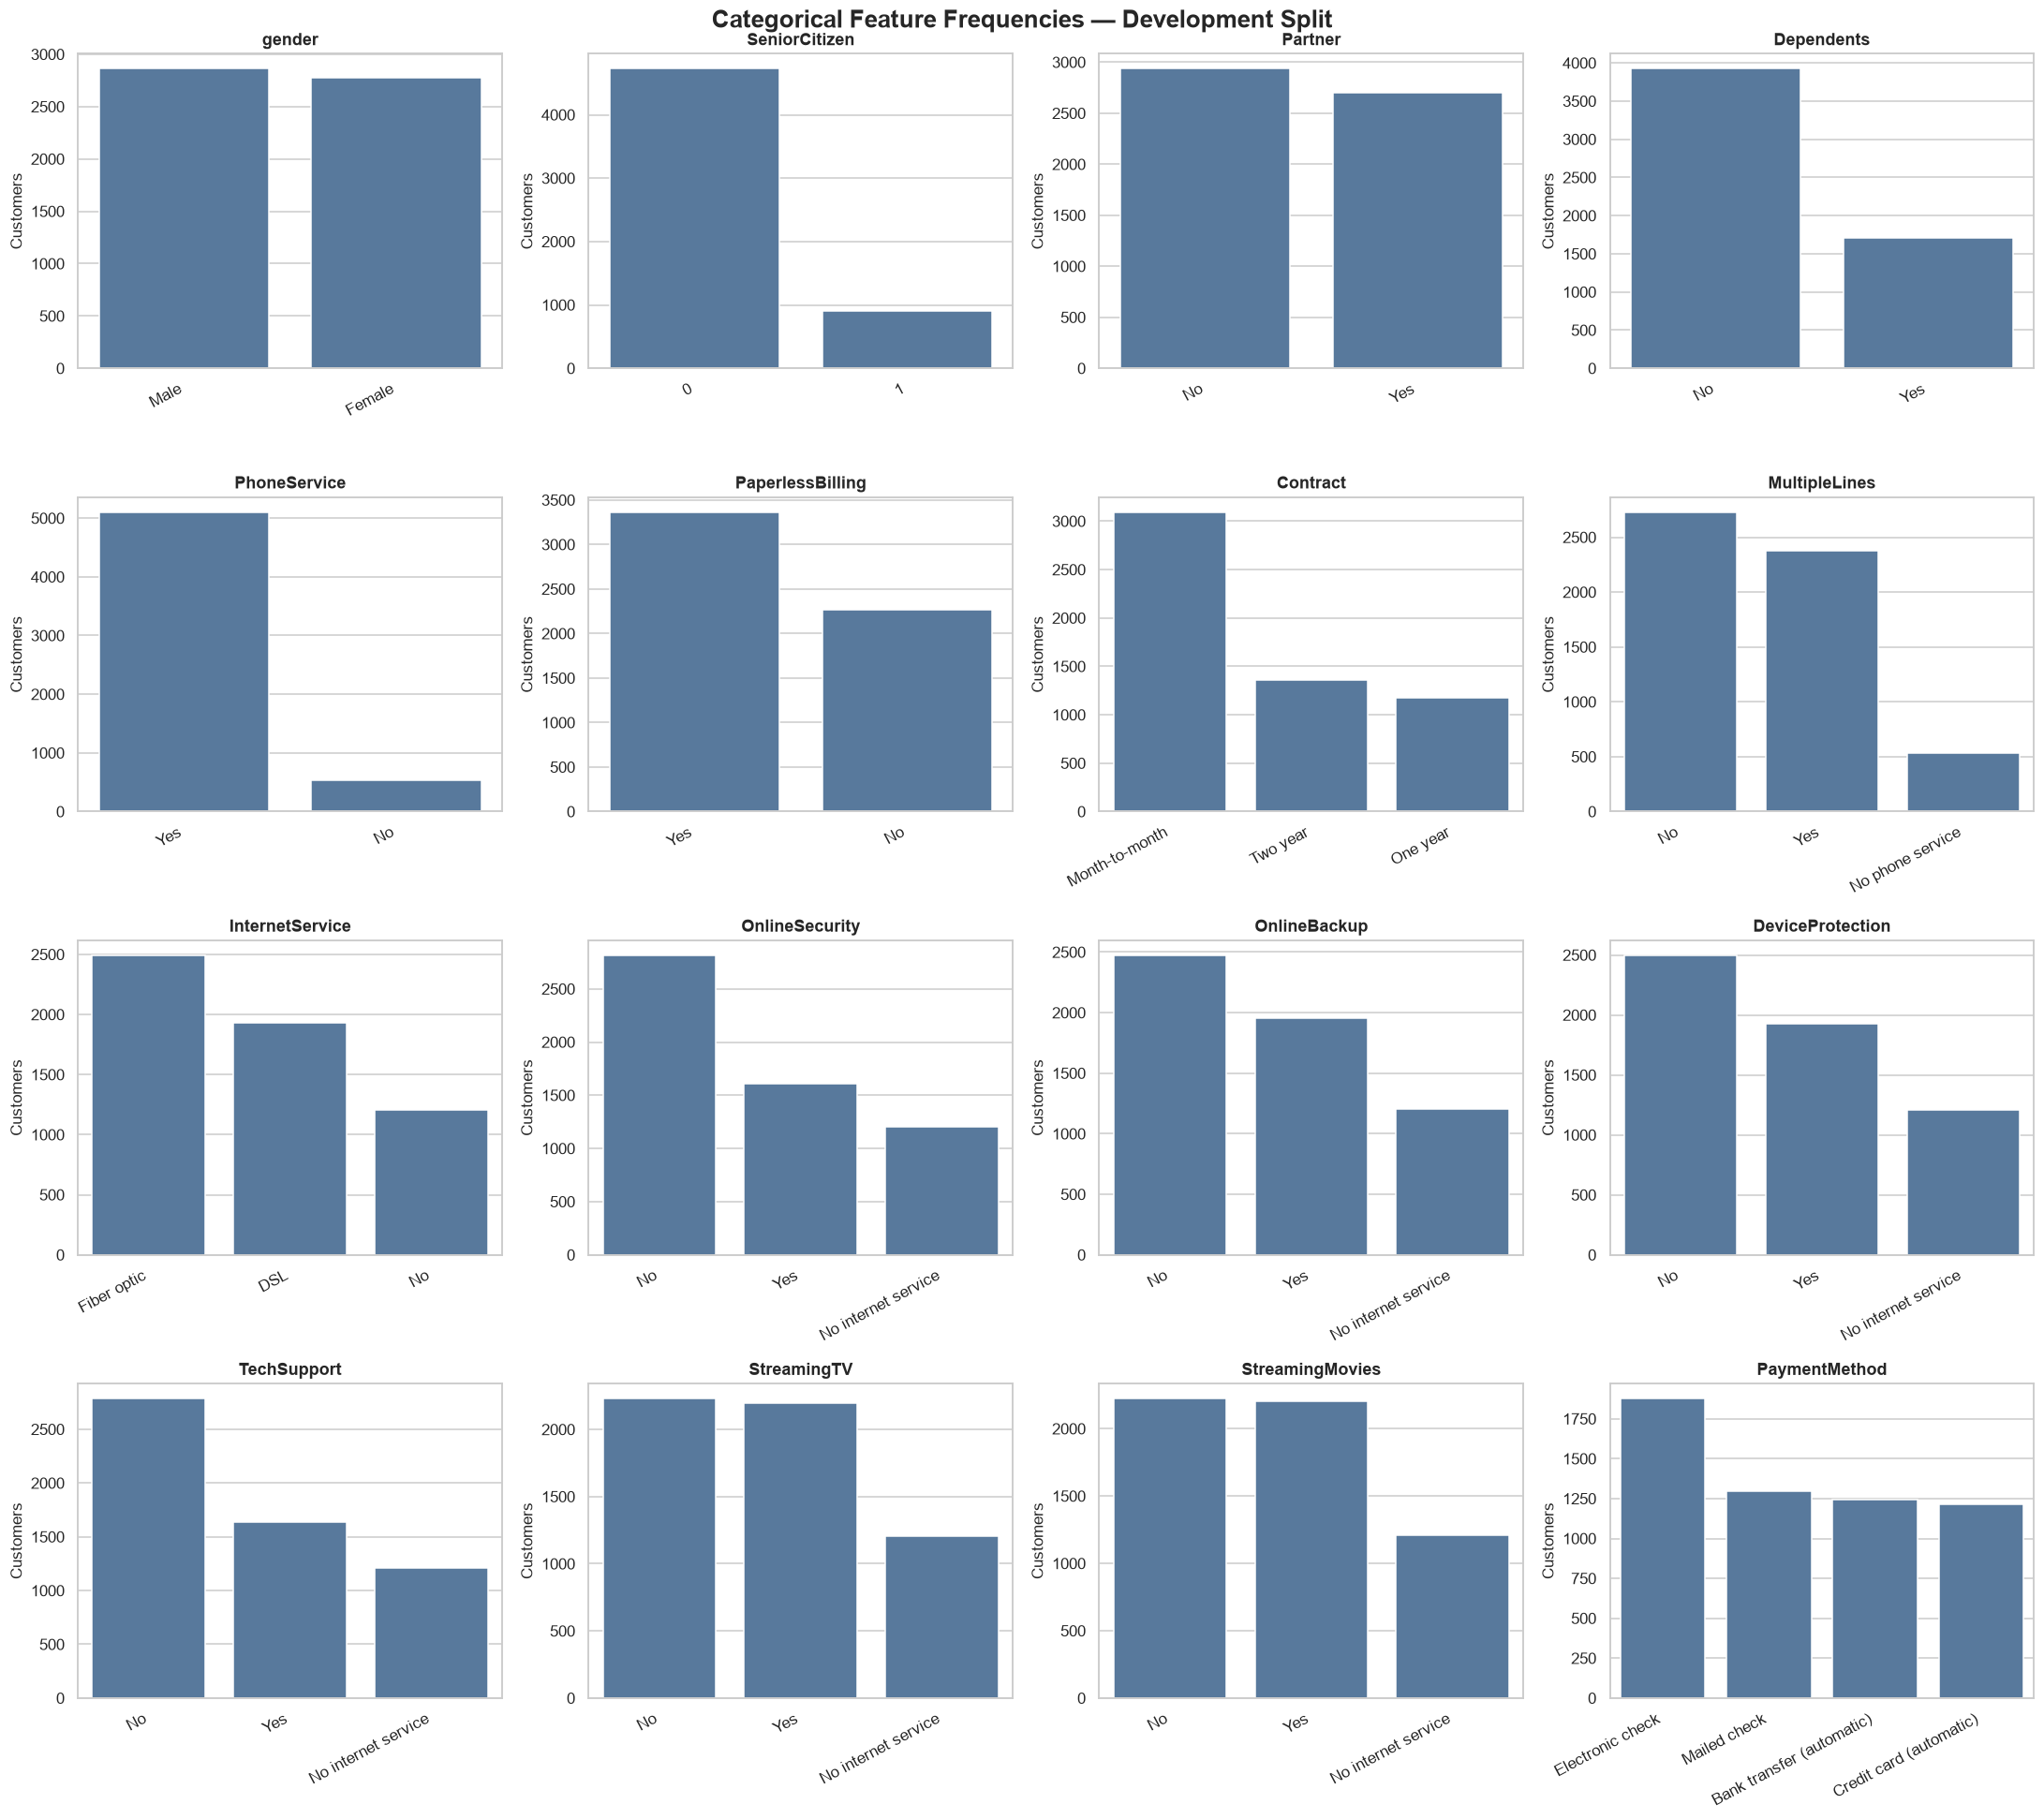

In [14]:
# ruff: noqa: E501
fig, axes = plt.subplots(4, 4, figsize=(20, 18))
for axis, column in zip(axes.flat, categorical_features, strict=False):
    order = df[column].value_counts().index
    sns.countplot(data=df, x=column, order=order, color="#4C78A8", ax=axis)
    axis.set(title=column, xlabel="", ylabel="Customers")
    axis.tick_params(axis="x", rotation=28)
    for label in axis.get_xticklabels():
        label.set_horizontalalignment("right")
for axis in axes.flat[len(categorical_features) :]:
    axis.set_visible(False)
fig.suptitle(
    "Categorical Feature Frequencies — Development Split",
    fontsize=17,
    fontweight="bold",
)
fig.tight_layout()
plt.show()

## 8.2 Categorical percentage distributions

These plots show the same composition normalized to 100%. Percentage labels reduce the
need to estimate values from an axis. For telecom planning, the panels reveal the mix of
contract, payment, connectivity, and add-on-service states in the development population.
They remain univariate: no statement is made about churn or causal retention drivers.

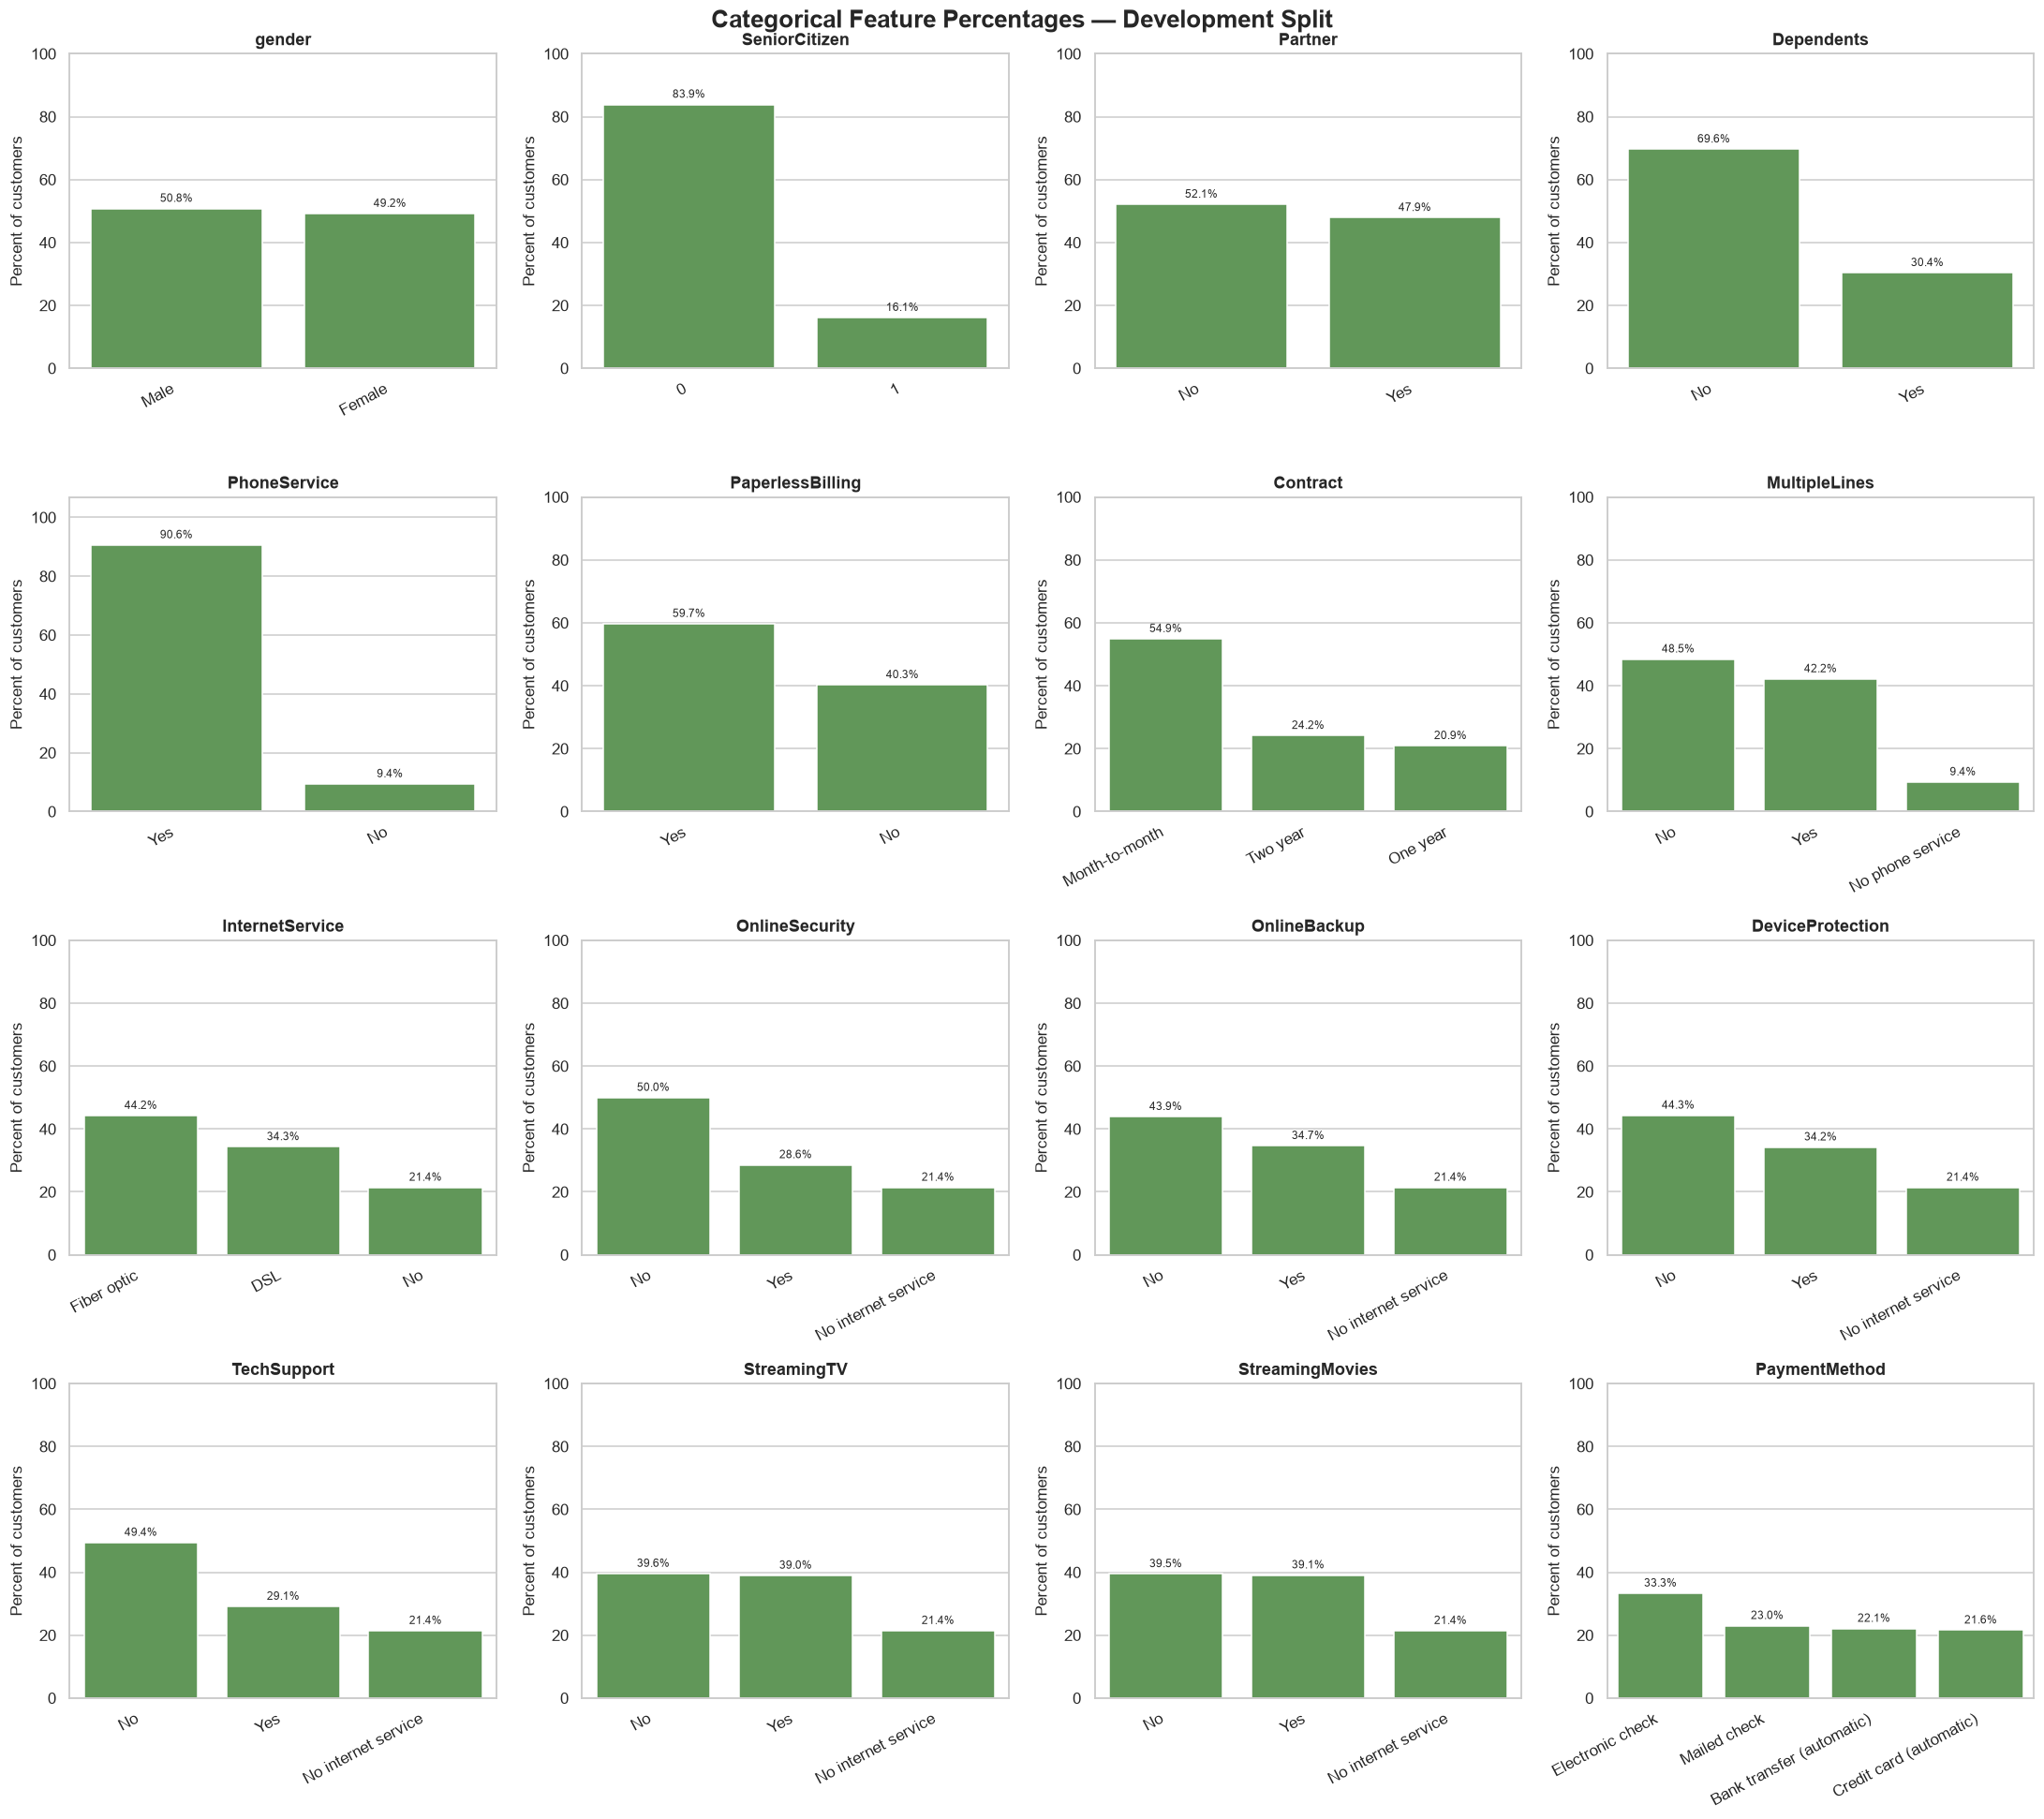

In [15]:
# ruff: noqa: E501
fig, axes = plt.subplots(4, 4, figsize=(20, 18))
for axis, column in zip(axes.flat, categorical_features, strict=False):
    percentages = df[column].value_counts(normalize=True).mul(100)
    sns.barplot(
        x=percentages.index.astype(str), y=percentages.values, color="#59A14F", ax=axis
    )
    axis.set(
        title=column,
        xlabel="",
        ylabel="Percent of customers",
        ylim=(0, max(100, percentages.max() * 1.18)),
    )
    axis.tick_params(axis="x", rotation=28)
    for label in axis.get_xticklabels():
        label.set_horizontalalignment("right")
    for patch, value in zip(axis.patches, percentages.values, strict=True):
        axis.annotate(
            f"{value:.1f}%",
            (patch.get_x() + patch.get_width() / 2, patch.get_height()),
            ha="center",
            va="bottom",
            fontsize=8,
            xytext=(0, 3),
            textcoords="offset points",
        )
for axis in axes.flat[len(categorical_features) :]:
    axis.set_visible(False)
fig.suptitle(
    "Categorical Feature Percentages — Development Split",
    fontsize=17,
    fontweight="bold",
)
fig.tight_layout()
plt.show()

## 9. Dataset-specific categorical interpretation

The following narrative is calculated from the loaded development split. It connects
univariate composition to possible business questions while carefully avoiding target
comparison or causal language.

In [16]:
# ruff: noqa: E501
def percentage(column: str, category: object) -> float:
    return df[column].eq(category).mean() * 100


display(
    Markdown(
        "\n".join(
            [
                f"- **Contract mix:** {percentage('Contract', 'Month-to-month'):.1f}% are month-to-month, "
                "so flexible-contract customers form the largest operational segment. Later work may "
                "compare outcomes by contract while controlling for tenure and services.",
                f"- **Connectivity:** {percentage('InternetService', 'Fiber optic'):.1f}% use fibre optic, "
                f"{percentage('InternetService', 'DSL'):.1f}% use DSL, and "
                f"{percentage('InternetService', 'No'):.1f}% report no internet service. Product messaging "
                "should recognize these materially different service contexts.",
                f"- **Billing:** {percentage('PaperlessBilling', 'Yes'):.1f}% use paperless billing; "
                f"electronic check is the most common payment method at "
                f"{percentage('PaymentMethod', 'Electronic check'):.1f}%.",
                f"- **Demographics:** integer-coded `SeniorCitizen=1` represents "
                f"{percentage('SeniorCitizen', 1):.1f}% of customers. It must remain categorical in later "
                "modelling and fairness review.",
                f"- **Service-state semantics:** exactly {percentage('InternetService', 'No'):.1f}% have no "
                "internet service, matching the repeated `No internet service` category in internet add-ons. "
                "That label is a valid structural state, not a missing value.",
            ]
        )
    )
)

- **Contract mix:** 54.9% are month-to-month, so flexible-contract customers form the largest operational segment. Later work may compare outcomes by contract while controlling for tenure and services.
- **Connectivity:** 44.2% use fibre optic, 34.3% use DSL, and 21.4% report no internet service. Product messaging should recognize these materially different service contexts.
- **Billing:** 59.7% use paperless billing; electronic check is the most common payment method at 33.3%.
- **Demographics:** integer-coded `SeniorCitizen=1` represents 16.1% of customers. It must remain categorical in later modelling and fairness review.
- **Service-state semantics:** exactly 21.4% have no internet service, matching the repeated `No internet service` category in internet add-ons. That label is a valid structural state, not a missing value.

# 10. Data-quality observations and scope checks

Descriptive analysis can reveal suspicious values but cannot decide validity without
business rules. In particular, zero tenure and zero total charges may describe newly
started accounts. Their alignment is checked below. Monetary units/currency are not
documented in the source columns, so values should not be presented as a known currency.

The final audit also confirms that only the configured development artifact is held as the
notebook's data source and that the row count was not changed by analysis.

In [17]:
# ruff: noqa: E501
zero_tenure = df["tenure"].eq(0)
zero_total = df["TotalCharges"].eq(0)
quality_checks = pd.Series(
    {
        "tenure_below_zero": int(df["tenure"].lt(0).sum()),
        "monthly_charges_below_zero": int(df["MonthlyCharges"].lt(0).sum()),
        "total_charges_below_zero": int(df["TotalCharges"].lt(0).sum()),
        "zero_tenure_rows": int(zero_tenure.sum()),
        "zero_total_charge_rows": int(zero_total.sum()),
        "zero_tenure_and_zero_total_rows": int((zero_tenure & zero_total).sum()),
        "zero_status_mismatch_rows": int((zero_tenure ^ zero_total).sum()),
    },
    name="count",
)
display(quality_checks.to_frame())

assert (
    development_path == (PROJECT_ROOT / "data/processed/development.parquet").resolve()
)
assert (
    len(df)
    == dimension_summary.loc[dimension_summary["metric"] == "Rows", "value"].iloc[0]
)
assert not zero_tenure.any() or (df.loc[zero_tenure, "TotalCharges"] == 0).all()
print(
    "Leakage/source audit passed: one configured development Parquet input was analysed."
)
print("No transformation or write operation was applied to the source dataset.")

,count
tenure_below_zero,0
monthly_charges_below_zero,0
total_charges_below_zero,0
zero_tenure_rows,10
zero_total_charge_rows,10
zero_tenure_and_zero_total_rows,10
zero_status_mismatch_rows,0


Leakage/source audit passed: one configured development Parquet input was analysed.
No transformation or write operation was applied to the source dataset.


# 11. Conclusions

## Key descriptive findings and business insights

- The development split contains **5,634 customers and 21 columns**. All columns are
  complete at the encoded-null level, and customer IDs are unique; this supports reliable
  row-level analysis while not ruling out semantic data errors.
- Median tenure is **29 months** (IQR **9–55**) and the mode is **1 month**. The mix
  includes both a notable newly acquired group and a mature customer base, suggesting
  lifecycle-aware communication may be more useful than one universal journey.
- Monthly charges average **65.03** dataset currency units (median **70.53**), with a
  broad, mildly left-skewed distribution. Pricing/service bundles appear heterogeneous,
  but plan data must be examined later before attributing the shape.
- Total charges average **2,291.43** versus a median of **1,395.53**, with skewness
  **0.962** and CV **99.4%**. Cumulative customer value is highly dispersed and right-
  skewed, consistent with the combined influence of tenure and recurring charges; that
  relationship is not tested here.
- Month-to-month contracts are the largest contract group (**54.9%**), fibre optic is the
  largest internet group (**44.2%**), paperless billing represents **59.7%**, and
  electronic check is the most common payment method (**33.3%**). These are population-
  mix observations, not churn-risk claims.

## Potential data-quality concerns and limitations

- Ten rows have both zero tenure and zero total charges. Their consistent pairing suggests
  new accounts or a documented validation rule, but source-system semantics should be
  confirmed before future modelling.
- `No internet service` and `No phone service` are legitimate structural categories, not
  nulls. Future encoders must preserve that distinction.
- The source does not specify the monetary currency, and `TotalCharges` may mechanically
  reflect tenure and monthly price. Units and billing adjustments should be documented.
- Results describe one stratified development sample. No confidence intervals, formal
  tests, time dimension, target relationships, causal effects, or population-generalization
  claims are included.

## Questions for later EDA stages

1. How does churn prevalence vary across tenure bands, contract types, and service states?
2. Are apparent contract differences confounded by tenure, price, or internet service?
3. How strongly do tenure and monthly charges jointly explain total charges, and where are
   billing inconsistencies?
4. Do rare combinations or subgroup patterns raise fairness, data-quality, or stability
   concerns?
5. Are nonlinear relationships or interactions visible in bivariate/multivariate plots?

These questions require later target, bivariate, multivariate, and inferential phases and
are intentionally not answered here.

# 12. Target Variable Analysis

## Phase 3A Step 6 scope

The preceding Step 5 deliberately stopped before target analysis. This appended section
now examines `Churn` **only within the configured development split**. Existing
configuration, `df`, `target_column`, visualization settings, and imports are reused.

The objectives are to quantify class balance, establish transparent no-skill baselines,
and measure observed monthly-charge exposure associated with churned accounts. This is
not feature analysis or model development: no customer predictors are transformed, no
sampling or class weighting is applied, and no conclusions about causal churn drivers
are drawn.

## 12.1 Target validity, frequencies, and class imbalance

For class $c$ among $n$ observations, its absolute frequency is $n_c$ and its relative
frequency is

$$p_c=\frac{n_c}{n},\qquad \text{percentage}_c=100p_c.$$

Here, **churn rate** is $n_{Yes}/n$ and **retention rate** is $n_{No}/n$. The
majority-to-minority imbalance ratio is

$$IR=\frac{n_{\text{majority}}}{n_{\text{minority}}}.$$

Class imbalance means one outcome is observed more often than the other. It matters
because a learning algorithm can achieve superficially high accuracy by favouring the
majority class while failing on the business-critical minority class.

There is no universally accepted threshold for calling imbalance mild, moderate, or
severe: consequences depend on sample size, error costs, model, and deployment context.
For transparent reporting only, this notebook uses the heuristic $IR<1.5$ “low”,
$1.5\le IR<3$ “moderate”, $3\le IR<10$ “substantial”, and $IR\ge10$ “severe”. This rubric
is a communication aid, not a statistical law.

In [18]:
# ruff: noqa: E501
expected_target_classes = {"No", "Yes"}
observed_target_classes = set(df[target_column].dropna().unique())

assert df[target_column].isna().sum() == 0, "Target contains missing values."
assert observed_target_classes == expected_target_classes, (
    f"Expected exactly {expected_target_classes}; observed {observed_target_classes}."
)

target_counts = (
    df[target_column]
    .value_counts()
    .reindex(["No", "Yes"])
    .rename("count")
)
target_relative_frequency = target_counts / len(df)

retention_count = int(target_counts["No"])
churn_count = int(target_counts["Yes"])
retention_rate = target_relative_frequency["No"]
churn_rate = target_relative_frequency["Yes"]
majority_class = target_counts.idxmax()
minority_class = target_counts.idxmin()
imbalance_ratio = target_counts.max() / target_counts.min()

if imbalance_ratio < 1.5:
    imbalance_severity = "Low"
elif imbalance_ratio < 3:
    imbalance_severity = "Moderate"
elif imbalance_ratio < 10:
    imbalance_severity = "Substantial"
else:
    imbalance_severity = "Severe"

target_distribution_summary = pd.DataFrame({
    "class": target_counts.index,
    "absolute_frequency": target_counts.values,
    "relative_frequency": target_relative_frequency.values,
    "percentage": target_relative_frequency.values * 100,
    "business_label": ["Retained", "Churned"],
})

target_overview_summary = pd.DataFrame([{
    "observations": len(df),
    "retention_count": retention_count,
    "churn_count": churn_count,
    "retention_rate": retention_rate,
    "churn_rate": churn_rate,
    "retention_percentage": retention_rate * 100,
    "churn_percentage": churn_rate * 100,
    "majority_class": majority_class,
    "minority_class": minority_class,
    "majority_to_minority_ratio": imbalance_ratio,
    "reporting_severity": imbalance_severity,
}])

display(target_distribution_summary)
display(target_overview_summary)
display(Markdown(
    f"**Observed development result:** {retention_count:,} customers "
    f"({retention_rate:.2%}) are retained and {churn_count:,} ({churn_rate:.2%}) "
    f"are churned. `No` is the majority class. The {imbalance_ratio:.2f}:1 ratio "
    f"is labelled **{imbalance_severity.lower()}** under the stated reporting rubric. "
    "The minority is still large enough for meaningful later evaluation, but majority-class "
    "bias remains a material risk."
))

,class,absolute_frequency,relative_frequency,percentage,business_label
0,No,4139,0.735,73.465,Retained
1,Yes,1495,0.265,26.535,Churned


,observations,retention_count,churn_count,retention_rate,churn_rate,retention_percentage,churn_percentage,majority_class,minority_class,majority_to_minority_ratio,reporting_severity
0,5634,4139,1495,0.735,0.265,73.465,26.535,No,Yes,2.769,Moderate


**Observed development result:** 4,139 customers (73.46%) are retained and 1,495 (26.54%) are churned. `No` is the majority class. The 2.77:1 ratio is labelled **moderate** under the stated reporting rubric. The minority is still large enough for meaningful later evaluation, but majority-class bias remains a material risk.

## 12.2 Target distribution visualizations

The three panels answer related but distinct questions:

1. **Count plot:** operational volume—how many customers are in each class. Labels give
   exact counts, which matter for campaign capacity and the number of observed churn cases.
2. **Percentage chart:** sample composition independent of total sample size. It makes the
   73.46%/26.54% split immediately comparable.
3. **Normalized stacked bar:** the whole development population is one 100% bar, making
   the retained/churned shares visually additive.

These plots show prevalence, not which features explain churn, when churn happened, or
whether any intervention would change the outcome.

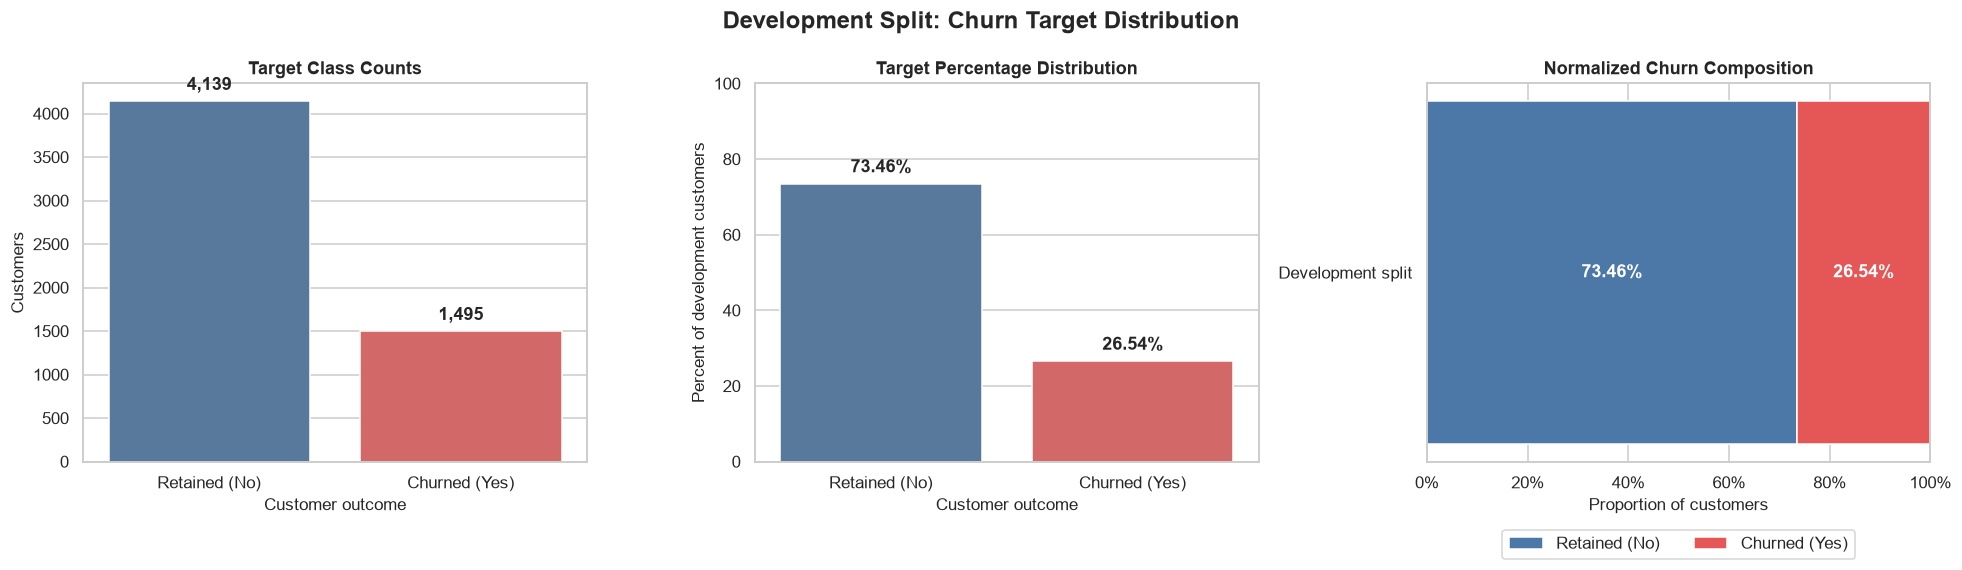

In [19]:
# ruff: noqa: E501
target_colors = {"No": "#4C78A8", "Yes": "#E45756"}
class_order = ["No", "Yes"]
class_labels = ["Retained (No)", "Churned (Yes)"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

sns.countplot(
    data=df,
    x=target_column,
    order=class_order,
    palette=target_colors,
    hue=target_column,
    legend=False,
    ax=axes[0],
)
axes[0].set(title="Target Class Counts", xlabel="Customer outcome", ylabel="Customers")
axes[0].set_xticks(range(2), class_labels)
for patch, count in zip(axes[0].patches, target_counts.values, strict=True):
    axes[0].annotate(
        f"{count:,}",
        (patch.get_x() + patch.get_width() / 2, patch.get_height()),
        ha="center",
        va="bottom",
        fontweight="bold",
        xytext=(0, 5),
        textcoords="offset points",
    )

target_percentages = target_relative_frequency.mul(100)
sns.barplot(
    x=class_labels,
    y=target_percentages.values,
    hue=class_order,
    palette=target_colors,
    legend=False,
    ax=axes[1],
)
axes[1].set(
    title="Target Percentage Distribution",
    xlabel="Customer outcome",
    ylabel="Percent of development customers",
    ylim=(0, 100),
)
for patch, value in zip(axes[1].patches, target_percentages.values, strict=True):
    axes[1].annotate(
        f"{value:.2f}%",
        (patch.get_x() + patch.get_width() / 2, patch.get_height()),
        ha="center",
        va="bottom",
        fontweight="bold",
        xytext=(0, 5),
        textcoords="offset points",
    )

left = 0.0
for target_class, label in zip(class_order, class_labels, strict=True):
    share = target_relative_frequency[target_class]
    axes[2].barh(
        ["Development split"],
        [share],
        left=left,
        color=target_colors[target_class],
        label=label,
    )
    axes[2].text(
        left + share / 2,
        0,
        f"{share:.2%}",
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
    )
    left += share
axes[2].set(
    title="Normalized Churn Composition",
    xlabel="Proportion of customers",
    ylabel="",
    xlim=(0, 1),
)
axes[2].xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
axes[2].legend(loc="lower center", bbox_to_anchor=(0.5, -0.28), ncol=2)

fig.suptitle(
    "Development Split: Churn Target Distribution",
    fontsize=16,
    fontweight="bold",
)
fig.tight_layout()
plt.show()

## 12.3 Majority-class baseline and the accuracy paradox

A majority-class classifier always predicts the most common outcome—here, `No`. Its
accuracy equals the retained-class prevalence:

$$\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}.$$

Treating `Churn=Yes` as positive, the confusion matrix is organized as:

| | Predicted No | Predicted Yes |
|---|---:|---:|
| **Actual No** | True Negative (TN) | False Positive (FP) |
| **Actual Yes** | False Negative (FN) | True Positive (TP) |

The remaining metrics are

$$\text{Precision}=\frac{TP}{TP+FP},\qquad
\text{Recall}=\frac{TP}{TP+FN},$$

$$F_1=2\frac{\text{Precision}\times\text{Recall}}
{\text{Precision}+\text{Recall}},$$

$$\text{Specificity}=\frac{TN}{TN+FP},\qquad
\text{Balanced Accuracy}=\frac{\text{Recall}+\text{Specificity}}{2}.$$

Precision asks, “Of customers flagged as churners, how many churned?” Recall asks, “Of
actual churners, how many were found?” Adjusting a real model's decision threshold often
trades precision against recall. The preferred balance depends on contact cost, offer
cost, customer experience, and the cost of a missed churner.

The **accuracy paradox** occurs when high accuracy coexists with useless minority-class
performance. An always-`No` rule can be correct for every retained customer while missing
every churner. When no positive prediction is made, $TP+FP=0$, so precision is
mathematically undefined; this notebook explicitly applies `zero_division=0`, reporting
precision as 0 rather than emitting an undefined value. F1 is also reported as 0.

In [20]:
# ruff: noqa: E501
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

y_true = df[target_column].eq("Yes").astype(int)
y_majority_prediction = np.zeros(len(y_true), dtype=int)

tn, fp, fn, tp = confusion_matrix(
    y_true,
    y_majority_prediction,
    labels=[0, 1],
).ravel()

majority_baseline_metrics = pd.DataFrame({
    "metric": [
        "Accuracy",
        "Precision (Yes)",
        "Recall / sensitivity (Yes)",
        "F1-score (Yes)",
        "Balanced accuracy",
        "Specificity (No recall)",
    ],
    "value": [
        accuracy_score(y_true, y_majority_prediction),
        precision_score(y_true, y_majority_prediction, zero_division=0),
        recall_score(y_true, y_majority_prediction, zero_division=0),
        f1_score(y_true, y_majority_prediction, zero_division=0),
        balanced_accuracy_score(y_true, y_majority_prediction),
        tn / (tn + fp),
    ],
})

majority_confusion_matrix = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual No", "Actual Yes"],
    columns=["Predicted No", "Predicted Yes"],
)

display(Markdown("**Hypothetical confusion matrix: always predict `No`**"))
display(majority_confusion_matrix)
display(majority_baseline_metrics.style.format({"value": "{:.4f}"}))
display(Markdown(
    f"**Observed interpretation:** the naive rule reaches {majority_baseline_metrics.loc[0, 'value']:.2%} "
    f"accuracy by correctly labelling all {tn:,} retained customers. However, its {fn:,} false "
    "negatives include every observed churner; positive-class precision, recall, and F1 are all "
    f"zero. Specificity is 100%, while balanced accuracy is {majority_baseline_metrics.loc[4, 'value']:.2%}. "
    "This is majority-class bias in its clearest form and demonstrates why raw accuracy is "
    "insufficient for retention modelling."
))

**Hypothetical confusion matrix: always predict `No`**

,Predicted No,Predicted Yes
Actual No,4139,0
Actual Yes,1495,0


,metric,value
0,Accuracy,0.7346
1,Precision (Yes),0.0000
2,Recall / sensitivity (Yes),0.0000
3,F1-score (Yes),0.0000
4,Balanced accuracy,0.5000
5,Specificity (No recall),1.0000


**Observed interpretation:** the naive rule reaches 73.46% accuracy by correctly labelling all 4,139 retained customers. However, its 1,495 false negatives include every observed churner; positive-class precision, recall, and F1 are all zero. Specificity is 100%, while balanced accuracy is 50.00%. This is majority-class bias in its clearest form and demonstrates why raw accuracy is insufficient for retention modelling.

## 12.4 Cross-validated `DummyClassifier` benchmark

`DummyClassifier(strategy="most_frequent")` learns only which class is most frequent in
each training fold and predicts that class for every validation observation. It is a
**no-skill benchmark**, not a useful predictive model: a later model should outperform it
on metrics aligned with the business objective.

Five-fold stratified cross-validation (read from configuration) partitions observations
so each validation fold approximately preserves the overall class proportion. **Stratified
splitting is not class balancing:** it does not create, remove, reweight, oversample, or
undersample any customer. It only distributes existing class labels across folds. Shuffling
uses the configured project random seed for reproducibility.

Metrics:

- **Accuracy:** overall correct fraction; vulnerable to majority-class dominance.
- **Balanced accuracy:** mean recall across the two classes; gives each class equal weight.
- **Precision, recall, F1:** evaluate `Yes` as the positive class and expose failure to find
  churners.
- **ROC-AUC:** probability that a randomly selected positive receives a higher score than
  a randomly selected negative; constant scores yield 0.5.
- **Average precision (AP):** a weighted mean of precision values achieved at successive
  recall increases,

$$AP=\sum_n(R_n-R_{n-1})P_n.$$

AP is **not** trapezoidal PR-AUC. Trapezoidal integration linearly interpolates between
precision-recall points and can be optimistic; AP uses stepwise recall increments. For a
constant no-skill score, AP is approximately the positive-class prevalence.

Cross-validation standard deviations describe fold-to-fold variation in this specific
split; they are not confidence intervals and do not measure future production drift.

In [21]:
# ruff: noqa: E501
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer
from sklearn.model_selection import StratifiedKFold, cross_validate

configured_cv_folds = int(config["validation"]["cv_folds"])
configured_random_state = int(config["project"]["random_state"])

cv = StratifiedKFold(
    n_splits=configured_cv_folds,
    shuffle=True,
    random_state=configured_random_state,
)

# DummyClassifier requires an X matrix but ignores its values for most_frequent.
# A one-column constant placeholder avoids using or transforming customer features.
dummy_X = np.zeros((len(df), 1), dtype=np.int8)

dummy_scoring = {
    "Accuracy": "accuracy",
    "Balanced accuracy": "balanced_accuracy",
    "Precision (Yes)": make_scorer(precision_score, zero_division=0),
    "Recall (Yes)": make_scorer(recall_score, zero_division=0),
    "F1-score (Yes)": make_scorer(f1_score, zero_division=0),
    "ROC-AUC": "roc_auc",
    "Average precision": "average_precision",
}

dummy_cv_raw = cross_validate(
    DummyClassifier(strategy="most_frequent"),
    dummy_X,
    y_true,
    cv=cv,
    scoring=dummy_scoring,
    return_train_score=False,
)

dummy_cv_folds = pd.DataFrame({
    metric: dummy_cv_raw[f"test_{metric}"]
    for metric in dummy_scoring
})
dummy_cv_summary = pd.DataFrame({
    "mean": dummy_cv_folds.mean(),
    "sample_standard_deviation": dummy_cv_folds.std(ddof=1),
}).rename_axis("metric")

display(Markdown(
    f"**Configuration:** {configured_cv_folds}-fold `StratifiedKFold`, "
    f"shuffle enabled, random seed {configured_random_state}."
))
display(dummy_cv_folds.style.format("{:.6f}"))
display(dummy_cv_summary.style.format("{:.6f}"))
display(Markdown(
    f"**Observed interpretation:** mean accuracy is {dummy_cv_summary.loc['Accuracy', 'mean']:.2%}, "
    f"but balanced accuracy is {dummy_cv_summary.loc['Balanced accuracy', 'mean']:.2%}; precision, "
    "recall, and F1 for churn are all zero. Constant class scores give ROC-AUC "
    f"{dummy_cv_summary.loc['ROC-AUC', 'mean']:.3f}. AP is "
    f"{dummy_cv_summary.loc['Average precision', 'mean']:.3f}, essentially the "
    f"{churn_rate:.3f} churn prevalence. A later model must be judged against these no-skill "
    "references using out-of-fold or held-out predictions, not training accuracy."
))

**Configuration:** 5-fold `StratifiedKFold`, shuffle enabled, random seed 42.

,Accuracy,Balanced accuracy,Precision (Yes),Recall (Yes),F1-score (Yes),ROC-AUC,Average precision
0,0.734694,0.500000,0.000000,0.000000,0.000000,0.500000,0.265306
1,0.734694,0.500000,0.000000,0.000000,0.000000,0.500000,0.265306
2,0.734694,0.500000,0.000000,0.000000,0.000000,0.500000,0.265306
3,0.734694,0.500000,0.000000,0.000000,0.000000,0.500000,0.265306
4,0.734458,0.500000,0.000000,0.000000,0.000000,0.500000,0.265542


,mean,sample_standard_deviation
metric,,
Accuracy,0.734647,0.000105
Balanced accuracy,0.500000,0.000000
Precision (Yes),0.000000,0.000000
Recall (Yes),0.000000,0.000000
F1-score (Yes),0.000000,0.000000
ROC-AUC,0.500000,0.000000
Average precision,0.265353,0.000105


**Observed interpretation:** mean accuracy is 73.46%, but balanced accuracy is 50.00%; precision, recall, and F1 for churn are all zero. Constant class scores give ROC-AUC 0.500. AP is 0.265, essentially the 0.265 churn prevalence. A later model must be judged against these no-skill references using out-of-fold or held-out predictions, not training accuracy.

## 12.5 Observed monthly-charge exposure

This section quantifies recurring charges currently associated with observed churned
accounts:

$$\text{Churn-associated share}=\frac{
\sum_{i:\,Churn_i=Yes}\text{MonthlyCharges}_i}{
\sum_{i=1}^{n}\text{MonthlyCharges}_i}\times100\%.$$

This is a descriptive exposure measure. It is **not** realized lost revenue, an annualized
forecast, customer lifetime value, preventable loss, or the causal benefit of a retention
programme. The dataset provides no churn date, post-churn billing, margin, intervention
cost, treatment response, or proof that any customer could have been retained. The source
also does not document a currency, so results remain in dataset currency units.

In [22]:
# ruff: noqa: E501
churn_mask = df[target_column].eq("Yes")
total_monthly_charge_exposure = df["MonthlyCharges"].sum()
churn_monthly_charge_exposure = df.loc[churn_mask, "MonthlyCharges"].sum()
churn_charge_share = churn_monthly_charge_exposure / total_monthly_charge_exposure
churn_average_monthly_charge = df.loc[churn_mask, "MonthlyCharges"].mean()
churn_median_monthly_charge = df.loc[churn_mask, "MonthlyCharges"].median()

monthly_charge_exposure_summary = pd.DataFrame([{
    "development_total_monthly_charges": total_monthly_charge_exposure,
    "churned_customer_monthly_charges": churn_monthly_charge_exposure,
    "churned_charge_share": churn_charge_share,
    "churned_charge_percentage": churn_charge_share * 100,
    "churned_average_monthly_charge": churn_average_monthly_charge,
    "churned_median_monthly_charge": churn_median_monthly_charge,
}])

display(monthly_charge_exposure_summary.style.format({
    "development_total_monthly_charges": "{:,.2f}",
    "churned_customer_monthly_charges": "{:,.2f}",
    "churned_charge_share": "{:.4f}",
    "churned_charge_percentage": "{:.2f}%",
    "churned_average_monthly_charge": "{:,.2f}",
    "churned_median_monthly_charge": "{:,.2f}",
}))
display(Markdown(
    f"**Observed development result:** total monthly charges are {total_monthly_charge_exposure:,.2f} "
    f"dataset currency units; {churn_monthly_charge_exposure:,.2f}, or {churn_charge_share:.2%}, "
    f"are associated with customers labelled `Churn=Yes`. Within that group, the average "
    f"monthly charge is {churn_average_monthly_charge:,.2f} and the median is "
    f"{churn_median_monthly_charge:,.2f}. This exposure is larger than the churned customer "
    f"share ({churn_rate:.2%}), but explaining that difference requires later bivariate analysis."
))

,development_total_monthly_charges,churned_customer_monthly_charges,churned_charge_share,churned_charge_percentage,churned_average_monthly_charge,churned_median_monthly_charge
0,"366,394.10","111,329.15",0.3039,30.39%,74.47,79.60


**Observed development result:** total monthly charges are 366,394.10 dataset currency units; 111,329.15, or 30.39%, are associated with customers labelled `Churn=Yes`. Within that group, the average monthly charge is 74.47 and the median is 79.60. This exposure is larger than the churned customer share (26.54%), but explaining that difference requires later bivariate analysis.

## 12.6 Step 6 conclusions and business findings

### Findings

- The development split contains **4,139 retained customers (73.46%)** and **1,495
  churned customers (26.54%)**. The majority-to-minority ratio is **2.77:1**, classified
  as **moderate** only under the explicitly stated reporting rubric.
- An always-`No` rule achieves **73.46% accuracy** but **0% churn precision, recall, and
  F1**. Its **100% specificity** and **50% balanced accuracy** expose the accuracy paradox:
  it recognizes only the majority class and provides no retention targeting value.
- Five-fold stratified `DummyClassifier` evaluation reproduces the no-skill result:
  accuracy **73.46%**, balanced accuracy **50%**, ROC-AUC **0.50**, and AP approximately
  **0.265**, while churn precision/recall/F1 remain zero.
- Churned accounts are associated with **111,329.15** of **366,394.10** total monthly-
  charge units (**30.39%**). Their average and median monthly charges are **74.47** and
  **79.60**. These values describe exposure only, not preventable or realized revenue loss.

### Evaluation guidance for later modelling

Accuracy should never be reported alone. Later phases should emphasize churn recall,
precision, F1, balanced accuracy, ROC-AUC, and especially precision-recall/AP because the
positive class is the operational focus. Final metric selection should reflect explicit
false-negative, false-positive, contact, and offer costs; probability calibration and
decision thresholds should also be assessed. The untouched test split must remain sealed
until the designated final evaluation stage.

### Limitations

- This is a static snapshot with no churn timestamp, observation window, or longitudinal
  behaviour.
- Monthly charges are not revenue, margin, lifetime value, or preventable loss; currency
  is undocumented.
- Stratified folds preserve prevalence but do not simulate temporal or production drift.
- The dummy benchmark ignores all predictors and therefore says nothing about learnable
  signal.
- No subgroup, feature-target, causal, fairness, calibration, or intervention analysis is
  performed in this step.

### Questions for the later bivariate phase

1. How does churn prevalence vary across tenure bands, contract types, internet services,
   and payment methods?
2. Do churn-associated monthly-charge differences persist after considering tenure and
   service mix?
3. Which categorical groups have sufficient support for stable churn-rate comparisons?
4. Are apparent group differences practically meaningful, and what uncertainty surrounds
   them?
5. Which variables may be redundant, structurally related, or potential leakage risks?